# T-RAG · Notebook 4 — New sources + temporal knowledge graph (GPU)

## About this notebook

**What it does :** News alone did not cover everything the project brief asked for, so this notebook adds the missing sources and builds the knowledge graph.

* **Social media :** 57,516 tweets about our companies, from September 2021 to September 2022, with exact timestamps. They also cover Meta and Netflix, which have no news.
* **Earnings reports :** the 136 earnings press releases from the companies' SEC 8-K filings, plus each quarter's reported revenue from the SEC's XBRL data. 88 quarters are linked to the press release that reported them.
* **Policy :** the texts of the Fed's 24 rate decisions, and 11 dated government actions such as chip export controls, the CHIPS Act and antitrust cases, with each affected company's stock reaction.

All new documents get FinBERT labels and bge vectors, so the old and new sources sit in one search index.

Next, Qwen2.5-7B-Instruct reads the documents around each event. It writes a one-line summary, the main driver (earnings, policy, product …) and the people, products and companies involved. These become a **time-stamped knowledge graph** (built with NetworkX) with 1,598 nodes and 4,269 dated links. The nodes are companies, events, entities, documents and months. An example link: "this policy action AFFECTS Nvidia on 2022-09-01, CAR −9.9%".

Finally, it repeats the mood-versus-price test with tweets. Again there is a same-day link, but no prediction of the next days.

**Needs :** Notebook 2's output and the Kaggle dataset "Stock Tweets for Sentiment Analysis and Prediction". GPU T4 ×2, internet on, about 22 minutes..

**Produces :** `trag_index_v2/`, the **final index** used by Notebooks 5, 7 and 8. It holds all documents, embeddings, events, coverage dates, the revenue tables and the graph.

In [1]:
# ============================ CONFIG ============================
from pathlib import Path

SEC_USER_AGENT = "IITB IE624 T-RAG student project (23b1311@iitb.ac.in)"   # SEC asks for a name + contact email
LLM_MODEL = "Qwen/Qwen2.5-7B-Instruct"          # explains events from that day's documents
FINBERT_MODEL = "ProsusAI/finbert"
START, END = "2021-01-01", "2023-12-31"

RUN = {"tweets": True, "sec": True, "fed": True, "llm_events": True}
MIN_MONTH_DOCS = {"news": 40, "social": 20}     # a source's coverage starts/ends at months with at least this many docs
MAX_DOCS_PER_EVENT = 8
LLM_BATCH = 8

ON_KAGGLE = Path("/kaggle/working").exists()
OUT = Path("/kaggle/working/trag_index_v2") if ON_KAGGLE else Path("trag_index_v2")
for sub in ("", "analysis", "figures", "graph"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT.resolve())

Output folder: /kaggle/working/trag_index_v2


In [2]:
!pip install -q sentence-transformers accelerate beautifulsoup4 networkx

In [3]:
import re, io, json, time, glob, shutil, pickle, warnings, traceback
import numpy as np
import pandas as pd
import requests
import torch
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 120)
N_GPU = torch.cuda.device_count()
DEV0 = "cuda:0" if N_GPU else "cpu"
print("torch", torch.__version__, "| GPUs:", N_GPU)
SUMMARY, T0 = {}, time.time()

TICKERS = ["TSLA", "AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "NFLX", "AMD", "INTC"]
COMPANY = {"TSLA": "Tesla", "AAPL": "Apple", "MSFT": "Microsoft", "NVDA": "Nvidia", "AMZN": "Amazon",
           "META": "Meta", "GOOGL": "Alphabet", "NFLX": "Netflix", "AMD": "AMD", "INTC": "Intel", "ALL": "the market"}

torch 2.11.0+cu130 | GPUs: 2


## Step 1 — Load Notebook 2's index

In [4]:
def find_input(name, folder="trag_index"):
    hits = sorted(glob.glob(f"/kaggle/input/**/{folder}/{name}", recursive=True)) + sorted(glob.glob(f"{folder}/{name}"))
    if not hits:
        raise FileNotFoundError(f"{folder}/{name} not found — attach Notebook 2's output (Add Data → Notebook Output Files).")
    return hits[0]

chunks1 = pd.read_parquet(find_input("chunks.parquet"))
E1 = np.load(find_input("embeddings_bge.npy"))
events = pd.read_parquet(find_input("events_labeled.parquet"))
prices = pd.read_parquet(find_input("prices.parquet"))
TRADING_DAYS = pd.DatetimeIndex(pd.read_parquet(find_input("trading_days.parquet"))["date"])
manifest2 = json.loads(Path(find_input("manifest_nb2.json")).read_text())
EMBED_MODEL, QUERY_PREFIX = manifest2["embedder"], manifest2["query_prefix"]
assert len(chunks1) == len(E1)
chunks1["source"] = "news"
events["day0"] = pd.to_datetime(events.day0); events["event_date"] = pd.to_datetime(events.event_date)
print(f"news chunks {len(chunks1):,} | events {len(events):,} | trading days {len(TRADING_DAYS)}")

TD = TRADING_DAYS.values.astype("datetime64[ns]")

def next_trading_day(dates, same_day_ok=True):
    d = pd.to_datetime(pd.Series(dates)).dt.normalize().values.astype("datetime64[ns]")
    idx = np.searchsorted(TD, d, side="left" if same_day_ok else "right")
    out = np.full(len(d), np.datetime64("NaT", "ns"), dtype="datetime64[ns]")
    ok = idx < len(TD)
    out[ok] = TD[idx[ok]]
    return pd.DatetimeIndex(out)

def day0_from_utc(ts_utc):
    """First trading day whose 16:00 New York close comes after the timestamp."""
    ts_utc = pd.Series(pd.to_datetime(ts_utc, utc=True))
    et = ts_utc.dt.tz_convert("America/New_York")
    d = et.dt.tz_localize(None).dt.normalize()
    d = d.where(et.dt.hour < 16, d + pd.Timedelta(days=1))
    return pd.Series(next_trading_day(d.values), index=ts_utc.index)

news chunks 49,993 | events 718 | trading days 997


## Step 2 — Social media: tweets

The Kaggle dataset has tweets about the most-watched tickers from 30 Sep 2021 to 30 Sep 2022, **with exact timestamps**. We keep our 10 companies (`GOOG` → `GOOGL`), strip links and retweet prefixes, and remove duplicate texts. Each tweet gets a stable ID (a hash of ticker, timestamp and text), so Notebook 4J labels exactly the same tweets.

In [5]:
import hashlib
TWEET_MAP = {"TSLA": "TSLA", "AAPL": "AAPL", "MSFT": "MSFT", "NVDA": "NVDA", "AMZN": "AMZN", "META": "META",
             "FB": "META", "GOOG": "GOOGL", "GOOGL": "GOOGL", "NFLX": "NFLX", "AMD": "AMD", "INTC": "INTC"}

def find_tweets_csv():
    hits = sorted(glob.glob("/kaggle/input/**/stock_tweets.csv", recursive=True)) + sorted(glob.glob("stock_tweets.csv"))
    if not hits:
        hits = [f for f in sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True)) if "tweet" in Path(f).name.lower()]
    return hits[0] if hits else None

def tweet_id(t, raw_date, raw_text):
    return "tw_" + hashlib.md5(f"{t}|{raw_date}|{raw_text}".encode("utf-8", "ignore")).hexdigest()[:12]

def load_tweets(path, start="2021-01-01", end="2023-12-31"):
    raw = pd.read_csv(path, dtype=str, on_bad_lines="skip")
    cols = {c.strip().lower(): c for c in raw.columns}
    pick = lambda *names: next((cols[n] for n in names if n in cols), None)
    dc = pick("date", "datetime", "created_at") or next(c for k, c in cols.items() if "date" in k)
    xc = pick("tweet", "text", "content") or next(c for k, c in cols.items() if "tweet" in k or "text" in k)
    sc = pick("stock name", "stock_name", "ticker", "symbol") or next(c for k, c in cols.items() if "stock" in k or "ticker" in k)
    print("Tweet columns used:", {"date": dc, "text": xc, "ticker": sc}, "| rows:", len(raw))
    d = pd.DataFrame({"raw_date": raw[dc].astype(str), "raw_text": raw[xc].fillna("").astype(str),
                      "sym": raw[sc].fillna("").astype(str).str.upper().str.strip()})
    d["ticker"] = d.sym.map(TWEET_MAP)
    d = d[d.ticker.notna()].copy()
    d["published_at"] = pd.to_datetime(d.raw_date, utc=True, errors="coerce", format="mixed")
    d = d[d.published_at.notna()]
    d = d[(d.published_at >= pd.Timestamp(start, tz="UTC")) & (d.published_at < pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1))]
    txt = d.raw_text.str.replace(r"^RT @\w+:\s*", "", regex=True).str.replace(r"https?://\S+", "", regex=True)
    d["text"] = txt.str.replace("&amp;", "&", regex=False).str.replace(r"\s+", " ", regex=True).str.strip()
    d = d[d.text.str.len() >= 25]
    d["norm"] = d.text.str.lower().str.replace(r"[^a-z0-9$ ]", " ", regex=True).str.split().str.join(" ")
    d = d.sort_values("published_at").drop_duplicates(["ticker", "norm"])
    d["doc_id"] = [tweet_id(t, a, b) for t, a, b in zip(d.ticker, d.raw_date, d.raw_text)]
    d = d.drop_duplicates("doc_id").drop(columns=["norm", "sym"]).reset_index(drop=True)
    print("Tweets kept per ticker:", d.ticker.value_counts().to_dict())
    return d

tweet_docs = pd.DataFrame()
try:
    if RUN["tweets"]:
        path = find_tweets_csv()
        if path is None:
            raise FileNotFoundError("stock_tweets.csv not found — add the Kaggle dataset 'Stock Tweets for Sentiment Analysis and Prediction'.")
        tw = load_tweets(path, START, END)
        tw["day0"] = day0_from_utc(tw.published_at).values
        tweet_docs = pd.DataFrame({
            "doc_id": tw.doc_id, "ticker": tw.ticker, "source": "social", "tickers_mentioned": tw.ticker,
            "published_at": tw.published_at, "available_at": tw.published_at, "time_missing": False,
            "day0": tw.day0, "title": tw.text.str.slice(0, 120), "text_for_scoring": tw.text.str.slice(0, 600),
            "url": ""})
        tweet_docs = tweet_docs[tweet_docs.day0.notna()].reset_index(drop=True)
        print(f"✔ {len(tweet_docs):,} tweets | {tweet_docs.published_at.min():%Y-%m-%d} → {tweet_docs.published_at.max():%Y-%m-%d}")
except Exception:
    traceback.print_exc(); print("⚠️ Tweets skipped.")
SUMMARY["tweets"] = tweet_docs.ticker.value_counts().to_dict() if len(tweet_docs) else 0

Tweet columns used: {'date': 'Date', 'text': 'Tweet', 'ticker': 'Stock Name'} | rows: 80793
Tweets kept per ticker: {'TSLA': 36515, 'AAPL': 4930, 'MSFT': 4005, 'AMZN': 4005, 'META': 2679, 'AMD': 2182, 'NFLX': 1653, 'GOOGL': 1241, 'INTC': 306}
✔ 57,516 tweets | 2021-09-30 → 2022-09-29


## Step 3 — Earnings reports: press releases (SEC 8-K Exhibit 99.1) and reported revenue (SEC XBRL)

* For every 8-K with **Item 2.02** (results of operations) in 2021–2023, we open the filing index and download **Exhibit 99.1**, the press release. Its **acceptance timestamp** (UTC) becomes the document's publication time. Each release is split into up to 4 chunks.
* From the SEC's **XBRL company facts** we take each company's **quarterly revenue** as first reported (earliest filing).
* We then link each quarter to the press release that reported it: the first release filed within 70 days after the quarter ended whose text contains that revenue figure. These links become questions in Notebook 5. The **answer comes from XBRL**, independent of the text and of FinBERT.

In [6]:
from bs4 import BeautifulSoup
CIK = {"TSLA": 1318605, "AAPL": 320193, "MSFT": 789019, "NVDA": 1045810, "AMZN": 1018724,
       "META": 1326801, "GOOGL": 1652044, "NFLX": 1065280, "AMD": 2488, "INTC": 50863}

def sec_get(url, kind="json", tries=3):
    for k in range(tries):
        try:
            r = requests.get(url, headers={"User-Agent": SEC_USER_AGENT, "Accept-Encoding": "gzip, deflate"}, timeout=40)
            if r.status_code == 200:
                time.sleep(0.15)                                # well below the SEC's 10 requests/second
                return r.json() if kind == "json" else r.text
            if r.status_code in (403, 404):
                print(f"  SEC {r.status_code}: {url}"); return None
        except Exception as e:
            print("  SEC error:", e)
        time.sleep(2 * (k + 1))
    return None

def html_to_text(html):
    try:
        soup = BeautifulSoup(html, "lxml")
    except Exception:
        soup = BeautifulSoup(html, "html.parser")
    for tag in soup(["script", "style", "head", "title"]):
        tag.decompose()
    return re.sub(r"\s+", " ", soup.get_text(" ").replace("\xa0", " ")).strip()

def sec_202_filings(t):
    j = sec_get(f"https://data.sec.gov/submissions/CIK{CIK[t]:010d}.json")
    if j is None: return pd.DataFrame()
    frames = [pd.DataFrame(j["filings"]["recent"])]
    for f in j["filings"].get("files", []):
        if f.get("filingTo", "9999") >= "2020-12-01":
            jj = sec_get("https://data.sec.gov/submissions/" + f["name"])
            if jj: frames.append(pd.DataFrame(jj))
    df = pd.concat(frames, ignore_index=True)
    df = df[(df["form"] == "8-K") & (df["filingDate"] >= START) & (df["filingDate"] <= END)]
    df = df[df["items"].fillna("").str.contains(r"(?:^|,)\s*2\.02\b")].copy()
    df["ticker"] = t
    return df[["ticker", "accessionNumber", "filingDate", "acceptanceDateTime"]].drop_duplicates("accessionNumber")

ROW_RE = re.compile(r"<tr[^>]*>(.*?)</tr>", re.S | re.I)
def find_exhibit(index_html):
    best = None
    for row in ROW_RE.findall(index_html or ""):
        cells = [re.sub(r"<[^>]+>", "", c).strip().upper() for c in re.findall(r"<td[^>]*>(.*?)</td>", row, re.S | re.I)]
        href = re.search(r'href="([^"]+)"', row, re.I)
        if not href or not any(c.startswith("EX-99") for c in cells):
            continue
        h = href.group(1).replace("/ix?doc=", "")
        if not h.lower().endswith((".htm", ".html", ".txt")):
            continue
        if any(c in ("EX-99.1", "EX-99.01") for c in cells):
            return h
        best = best or h
    return best

def split_chunks(text, size=1400, max_chunks=4):
    sents, out, cur = re.split(r"(?<=[.!?])\s+", text), [], ""
    for s in sents:
        if len(cur) + len(s) > size and cur:
            out.append(cur.strip()); cur = ""
            if len(out) == max_chunks: break
        cur += " " + s
    if cur.strip() and len(out) < max_chunks: out.append(cur.strip())
    return [c[:size + 400] for c in out]

releases, filing_docs, xbrl = pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
try:
    if RUN["sec"]:
        fl = pd.concat([sec_202_filings(t) for t in TICKERS], ignore_index=True)
        print(f"8-K Item 2.02 filings 2021–2023: {len(fl)}", fl.ticker.value_counts().to_dict())
        rel_rows = []
        for r in fl.itertuples():
            acc, cik = r.accessionNumber, CIK[r.ticker]
            base = f"https://www.sec.gov/Archives/edgar/data/{cik}/{acc.replace('-', '')}"
            href = find_exhibit(sec_get(f"{base}/{acc}-index.htm", kind="text"))
            if not href:
                continue
            url = href if href.startswith("http") else ("https://www.sec.gov" + href if href.startswith("/") else f"{base}/{href}")
            html = sec_get(url, kind="text")
            if not html:
                continue
            text = html_to_text(html)[:400_000]          # full text is kept for matching the revenue figure
            if len(text) < 200:
                continue
            rel_rows.append({"ticker": r.ticker, "accession": acc, "filed": pd.Timestamp(r.filingDate),
                             "accepted": pd.to_datetime(r.acceptanceDateTime, utc=True, errors="coerce"), "url": url, "text": text})
        releases = pd.DataFrame(rel_rows)
        releases["accepted"] = pd.to_datetime(releases.accepted, utc=True)
        releases["accepted"] = releases.accepted.fillna(pd.to_datetime(releases.filed).dt.tz_localize("UTC") + pd.Timedelta(hours=21))
        releases["day0"] = day0_from_utc(releases.accepted).values
        print(f"✔ press releases downloaded: {len(releases)}", releases.ticker.value_counts().to_dict())
        rows = []
        for r in releases.itertuples():
            for k, ch in enumerate(split_chunks(r.text[:9000])):
                rows.append({"doc_id": f"fil_{r.ticker}_{r.accession.replace('-', '')}_{k}", "ticker": r.ticker, "source": "filing",
                             "tickers_mentioned": r.ticker, "published_at": r.accepted, "available_at": r.accepted,
                             "time_missing": False, "day0": r.day0,
                             "title": f"{COMPANY[r.ticker]} press release (8-K Item 2.02, Exhibit 99.1) filed {r.filed:%Y-%m-%d}"
                                      + ("" if k == 0 else f" — part {k+1}"),
                             "text_for_scoring": ch, "url": r.url, "accession": r.accession})
        filing_docs = pd.DataFrame(rows)
except Exception:
    traceback.print_exc(); print("⚠️ Press releases skipped.")
SUMMARY["press_releases"] = len(releases)

8-K Item 2.02 filings 2021–2023: 136 {'TSLA': 24, 'NVDA': 13, 'AMD': 13, 'INTC': 13, 'GOOGL': 13, 'AAPL': 12, 'META': 12, 'AMZN': 12, 'MSFT': 12, 'NFLX': 12}
✔ press releases downloaded: 136 {'TSLA': 24, 'NVDA': 13, 'AMD': 13, 'INTC': 13, 'GOOGL': 13, 'AAPL': 12, 'META': 12, 'AMZN': 12, 'MSFT': 12, 'NFLX': 12}


In [7]:
REV_TAGS = ["RevenueFromContractWithCustomerExcludingAssessedTax", "Revenues", "SalesRevenueNet",
            "RevenueFromContractWithCustomerIncludingAssessedTax"]

def xbrl_quarters(t):
    j = sec_get(f"https://data.sec.gov/api/xbrl/companyfacts/CIK{CIK[t]:010d}.json")
    if not j: return pd.DataFrame()
    gaap, rows = j.get("facts", {}).get("us-gaap", {}), []
    for tag in REV_TAGS:
        for unit, facts in gaap.get(tag, {}).get("units", {}).items():
            if unit != "USD": continue
            for f in facts:
                if "start" not in f or "end" not in f: continue
                s, e = pd.Timestamp(f["start"]), pd.Timestamp(f["end"])
                if not (80 <= (e - s).days <= 100) or e < pd.Timestamp("2020-09-01") or e > pd.Timestamp(END):
                    continue
                rows.append({"ticker": t, "tag": tag, "start": s, "end": e, "val": float(f["val"]),
                             "filed": pd.Timestamp(f["filed"]), "form": f.get("form"), "accn": f.get("accn")})
    df = pd.DataFrame(rows)
    if df.empty: return df
    return df.sort_values("filed").drop_duplicates(["tag", "start", "end"], keep="first")   # as first reported

def revenue_patterns(v):
    b, m, k = v / 1e9, v / 1e6, v / 1e3
    pats = [re.compile(r"\$?\s?" + re.escape(s) + r"\s*(?:billion|bn|b)\b", re.I) for s in {f"{b:.1f}", f"{b:.2f}"}]
    for s in {f"{m:,.0f}", f"{k:,.0f}"}:
        if len(s) >= 5:
            pats.append(re.compile(r"(?<![\d.,])" + re.escape(s) + r"(?![\d,])"))
    return pats

release_facts = pd.DataFrame()
try:
    if RUN["sec"] and len(releases):
        xbrl = pd.concat([xbrl_quarters(t) for t in TICKERS], ignore_index=True)
        print("XBRL quarterly revenue facts:", len(xbrl), xbrl.groupby("ticker").size().to_dict() if len(xbrl) else {})
        rows, extra = [], []
        for t in TICKERS:
            q = xbrl[(xbrl.ticker == t) & (xbrl.end >= pd.Timestamp("2020-12-01"))] if len(xbrl) else xbrl
            rel_t = releases[releases.ticker == t].sort_values("accepted")
            if len(q) == 0 or len(rel_t) == 0: continue
            for (s, e), g in q.groupby(["start", "end"]):
                g = g.sort_values("val", ascending=False)               # total revenue ≥ any revenue sub-total
                cand = rel_t[(rel_t.filed > e) & (rel_t.filed <= e + pd.Timedelta(days=70))]
                found = None
                for r in cand.itertuples():
                    for f in g.itertuples():
                        m = next((mm for p in revenue_patterns(f.val) for mm in [p.search(r.text)] if mm), None)
                        if m: found = (r, f, m); break
                    if found: break
                if not found: continue
                r, f, m = found
                fd = filing_docs[filing_docs.accession == r.accession]
                hit = [d for d, txt in zip(fd.doc_id, fd.text_for_scoring) if m.group(0) in txt]
                if hit:
                    fact_doc = hit[0]
                else:                                                  # add a chunk around the figure
                    p0 = max(0, m.start() - 600)
                    fact_doc = f"fil_{t}_{r.accession.replace('-', '')}_{9}"
                    extra.append({**fd.iloc[0].to_dict(), "doc_id": fact_doc, "text_for_scoring": r.text[p0:p0 + 1400],
                                  "title": fd.iloc[0].title.split(" — ")[0] + " — financial results section"})
                rows.append({"ticker": t, "tag": f.tag, "period_start": s, "period_end": e,
                             "revenue_usd": f.val, "revenue_bn": round(f.val / 1e9, 3), "release_accession": r.accession,
                             "release_filed": r.filed, "release_accepted": r.accepted, "release_day0": r.day0,
                             "fact_doc_id": fact_doc, "matched_text": m.group(0)})
        if extra:
            filing_docs = pd.concat([filing_docs, pd.DataFrame(extra)], ignore_index=True).drop_duplicates("doc_id")
        release_facts = pd.DataFrame(rows)
        print(f"✔ quarters linked to a press release that states the revenue: {len(release_facts)}",
              release_facts.ticker.value_counts().to_dict() if len(release_facts) else {})
        if len(release_facts):
            print(release_facts.groupby("ticker").tail(1)[["ticker", "period_end", "revenue_bn", "release_filed", "matched_text"]].to_string(index=False))
except Exception:
    traceback.print_exc(); print("⚠️ XBRL step skipped.")
SUMMARY["revenue_quarters_linked"] = len(release_facts)

XBRL quarterly revenue facts: 112 {'AAPL': 11, 'AMD': 11, 'AMZN': 11, 'GOOGL': 12, 'INTC': 10, 'META': 10, 'MSFT': 11, 'NFLX': 11, 'NVDA': 10, 'TSLA': 15}
✔ quarters linked to a press release that states the revenue: 88 {'NFLX': 10, 'AMZN': 10, 'AMD': 10, 'AAPL': 9, 'META': 9, 'MSFT': 9, 'GOOGL': 9, 'NVDA': 9, 'INTC': 9, 'TSLA': 4}
ticker period_end  revenue_bn release_filed   matched_text
  TSLA 2023-09-30      23.350    2023-10-18         $23.4B
  AAPL 2023-07-01      81.797    2023-08-03  $81.8 billion
  MSFT 2023-09-30      56.517    2023-10-24  $56.5 billion
  NVDA 2023-10-29      18.120    2023-11-21 $18.12 billion
  AMZN 2023-09-30     143.083    2023-10-26 $143.1 billion
  META 2023-09-30      34.146    2023-10-25 $34.15 billion
 GOOGL 2023-09-30      76.693    2023-10-24         76,693
  NFLX 2023-09-30       8.542    2023-10-18          $8.5B
   AMD 2023-09-30       5.800    2023-10-31   $5.8 billion
  INTC 2023-09-30      14.158    2023-10-26  $14.2 billion


## Step 4 — Policy changes: Fed statements and dated government actions

* **FOMC statements**: the text of all 24 rate decisions in 2021–2023, published at 2:00 pm New York time. They are stored as market-wide documents (`ticker = ALL`).
* **Policy actions**: a hand-checked list of 11 dated government actions that targeted our companies. For each affected company we compute the abnormal return on day 0 and CAR[−1,+3], exactly as for other events.

In [8]:
FOMC_DATES = pd.to_datetime([
    "2021-01-27","2021-03-17","2021-04-28","2021-06-16","2021-07-28","2021-09-22","2021-11-03","2021-12-15",
    "2022-01-26","2022-03-16","2022-05-04","2022-06-15","2022-07-27","2022-09-21","2022-11-02","2022-12-14",
    "2023-02-01","2023-03-22","2023-05-03","2023-06-14","2023-07-26","2023-09-20","2023-11-01","2023-12-13"])

def fomc_text(d):
    url = f"https://www.federalreserve.gov/newsevents/pressreleases/monetary{d:%Y%m%d}a.htm"
    try:
        r = requests.get(url, headers={"User-Agent": "Mozilla/5.0 (IIT Bombay IE624 student project)"}, timeout=30)
        if r.status_code != 200: return None, url
    except Exception:
        return None, url
    text = html_to_text(r.text)
    t0 = max(text.find("FOMC statement"), 0)
    starts = [text.find(k, t0) for k in ("Recent indicators", "Indicators of economic activity", "The Federal Reserve is committed",
                                         "Economic activity", "Russia's", "The U.S. banking system", "Inflation remains")]
    starts = [s for s in starts if s >= 0]
    i = min(starts) if starts else t0
    ends = [text.find(k, i) for k in ("Voting for the monetary policy action", "Implementation Note", "For media inquiries")]
    ends = [e for e in ends if e > i]
    body = text[i:min(ends) if ends else i + 3500][:3500]
    # put the rate decision first, so it is never cut off and always appears in the evidence snippet
    key = [s for s in re.split(r"(?<=[.!?])\s+", body) if re.search(r"decided to|target range for the federal funds rate", s)][:2]
    return (("DECISION: " + " ".join(key) + " | STATEMENT: ") if key else "") + body, url

fed_docs = pd.DataFrame()
try:
    if RUN["fed"]:
        rows = []
        for d in FOMC_DATES:
            body, url = fomc_text(d)
            if not body: continue
            pub = (pd.Timestamp(d) + pd.Timedelta(hours=14)).tz_localize("America/New_York").tz_convert("UTC")
            rows.append({"doc_id": f"fed_{d:%Y%m%d}", "ticker": "ALL", "source": "fed", "tickers_mentioned": "ALL",
                         "published_at": pub, "available_at": pub, "time_missing": False, "day0": d,
                         "title": f"FOMC statement {d:%Y-%m-%d}", "text_for_scoring": body[:2500], "url": url})
        fed_docs = pd.DataFrame(rows)
        print(f"✔ FOMC statements: {len(fed_docs)} / {len(FOMC_DATES)}")
        if len(fed_docs): print("  e.g.", fed_docs.text_for_scoring.iloc[-1][:250], "…")
except Exception:
    traceback.print_exc(); print("⚠️ Fed statements skipped.")
SUMMARY["fomc_statements"] = len(fed_docs)

# date announced, first trading day the market could react, companies targeted, description
POLICY_EVENTS = [
    ("2022-08-09", "2022-08-09", ["INTC", "AMD", "NVDA"], "the CHIPS and Science Act (US chip-manufacturing subsidies) was signed into law"),
    ("2022-08-16", "2022-08-16", ["TSLA"], "the Inflation Reduction Act, with new US electric-vehicle tax credits, was signed into law"),
    ("2022-08-31", "2022-09-01", ["NVDA", "AMD"], "the US government imposed a licence requirement on exports of top AI chips (Nvidia A100/H100) to China"),
    ("2022-10-07", "2022-10-10", ["NVDA", "AMD", "INTC"], "the US Commerce Department announced sweeping export controls on advanced chips to China"),
    ("2022-12-08", "2022-12-08", ["MSFT"], "the FTC sued to block Microsoft's acquisition of Activision Blizzard"),
    ("2023-01-24", "2023-01-24", ["GOOGL"], "the US Justice Department sued Google over its advertising-technology business"),
    ("2023-02-16", "2023-02-16", ["TSLA"], "the US safety regulator NHTSA announced a recall of about 363,000 Teslas with Full Self-Driving Beta"),
    ("2023-04-26", "2023-04-26", ["MSFT"], "the UK competition authority blocked Microsoft's Activision Blizzard deal"),
    ("2023-09-06", "2023-09-06", ["AAPL", "AMZN", "GOOGL", "META", "MSFT"], "the EU designated large tech companies as 'gatekeepers' under the Digital Markets Act"),
    ("2023-09-26", "2023-09-26", ["AMZN"], "the FTC and 17 US states sued Amazon for alleged monopoly practices"),
    ("2023-10-17", "2023-10-17", ["NVDA", "AMD", "INTC"], "the US tightened its export rules on AI chips to China"),
]
ar_w = prices[prices.ticker != "QQQ"].pivot(index="date", columns="ticker", values="ar")
z_w = prices[prices.ticker != "QQQ"].pivot(index="date", columns="ticker", values="z")
pos_ix = {d: i for i, d in enumerate(ar_w.index)}
def car(t, d0, lo=-1, hi=3):
    i = pos_ix.get(pd.Timestamp(d0))
    if i is None or i + lo < 0 or i + hi >= len(ar_w): return np.nan
    return ar_w[t].iloc[i + lo:i + hi + 1].sum(min_count=hi - lo + 1)

rows = []
for k, (ann, d0, tick, desc) in enumerate(POLICY_EVENTS):
    d0 = pd.Timestamp(d0)
    for t in tick:
        rows.append({"event_id": f"pol_{k:02d}_{t}", "policy_id": f"pol_{k:02d}", "ticker_scope": "POLICY", "ticker": t,
                     "day0": d0, "event_types": "policy", "sources": "curated policy list", "event_date": pd.Timestamp(ann),
                     "ar_day0": ar_w[t].get(d0, np.nan), "z_day0": z_w[t].get(d0, np.nan), "car_m1_p3": car(t, d0),
                     "overlaps_fomc": False, "label": "policy action", "description": desc})
policy_ev = pd.DataFrame(rows)
events_v2 = pd.concat([events.assign(description=np.nan, policy_id=np.nan), policy_ev], ignore_index=True)
print(policy_ev[["event_id", "ticker", "day0", "ar_day0", "car_m1_p3"]].round(3).to_string(index=False))

✔ FOMC statements: 24 / 24
  e.g. DECISION: In support of these goals, the Committee decided to maintain the target range for the federal funds rate at 5-1/4 to 5-1/2 percent. | STATEMENT: Recent indicators suggest that growth of economic activity has slowed from its strong pace in t …
    event_id ticker       day0  ar_day0  car_m1_p3
 pol_00_INTC   INTC 2022-08-09   -0.014     -0.001
  pol_00_AMD    AMD 2022-08-09   -0.028     -0.059
 pol_00_NVDA   NVDA 2022-08-09   -0.020     -0.060
 pol_01_TSLA   TSLA 2022-08-16   -0.007      0.016
 pol_02_NVDA   NVDA 2022-09-01   -0.076     -0.099
  pol_02_AMD    AMD 2022-09-01   -0.030     -0.074
 pol_03_NVDA   NVDA 2022-10-10   -0.014     -0.011
  pol_03_AMD    AMD 2022-10-10    0.005     -0.070
 pol_03_INTC   INTC 2022-10-10   -0.009      0.021
 pol_04_MSFT   MSFT 2022-12-08    0.000      0.022
pol_05_GOOGL  GOOGL 2023-01-24   -0.018     -0.034
 pol_06_TSLA   TSLA 2023-02-16   -0.029      0.030
 pol_07_MSFT   MSFT 2023-04-26    0.065      0.061

## Step 5 — FinBERT sentiment and bge embeddings for the new documents

The same models as Notebook 2, so the old and new documents share one index.

In [9]:
from transformers import AutoTokenizer as _AT, AutoModelForSequenceClassification

def finbert_probs(texts, model_name, batch=128, maxlen=256, name=""):
    tok = _AT.from_pretrained(model_name)
    fb = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEV0).eval()
    if DEV0 != "cpu": fb = fb.half()
    id2label = {int(k): v.lower() for k, v in fb.config.id2label.items()}
    cols = [next(i for i, v in id2label.items() if v.startswith(p)) for p in ("pos", "neg", "neu")]
    texts = pd.Series(list(texts), dtype="object").fillna("").astype(str)
    uniq, inv = np.unique(texts.values, return_inverse=True)
    order = np.argsort([len(u) for u in uniq])
    probs = np.zeros((len(uniq), 3), dtype=np.float32)
    t0, nb = time.time(), int(np.ceil(len(uniq) / batch))
    with torch.inference_mode():
        for b in range(nb):
            idx = order[b * batch:(b + 1) * batch]
            enc = tok([uniq[i] for i in idx], padding=True, truncation=True, max_length=maxlen, return_tensors="pt").to(DEV0)
            probs[idx] = fb(**enc).logits.float().softmax(-1).cpu().numpy()[:, cols]
            if b % 100 == 0 or b == nb - 1:
                print(f"  FinBERT {name}: batch {b+1}/{nb} | {time.time()-t0:5.0f}s")
    del fb
    if DEV0 != "cpu": torch.cuda.empty_cache()
    return probs[inv]        # columns: positive, negative, neutral

from sentence_transformers import SentenceTransformer
SRC_NAME = {"news": "news", "social": "social media", "filing": "SEC filing", "fed": "Federal Reserve"}
new_docs = pd.concat([d for d in (tweet_docs, filing_docs, fed_docs) if len(d)], ignore_index=True) \
           if any(len(d) for d in (tweet_docs, filing_docs, fed_docs)) else pd.DataFrame(columns=chunks1.columns)
if len(new_docs):
    P = finbert_probs(new_docs.text_for_scoring, FINBERT_MODEL, name="new docs")
    new_docs["score"] = P[:, 0] - P[:, 1]
    new_docs["label"] = np.array(["positive", "negative", "neutral"])[P.argmax(1)]
    new_docs["day0"] = pd.to_datetime(new_docs.day0)
    new_docs["chunk_text"] = ("[" + new_docs.ticker + " | " + new_docs.day0.dt.strftime("%Y-%m-%d") + " | "
                              + new_docs.source.map(SRC_NAME) + "] " + new_docs.text_for_scoring.astype(str))
    emb = SentenceTransformer(EMBED_MODEL, device=DEV0)
    if DEV0 != "cpu": emb = emb.half()
    t_e = time.time()
    E_new = emb.encode(new_docs.chunk_text.tolist(), batch_size=256, normalize_embeddings=True,
                       convert_to_numpy=True, show_progress_bar=False).astype(np.float16)
    print(f"Embedded {len(new_docs):,} new documents in {time.time()-t_e:.0f}s")
    del emb
    if N_GPU: torch.cuda.empty_cache()
else:
    E_new = np.zeros((0, E1.shape[1]), np.float16)

KEEP = ["doc_id", "ticker", "source", "tickers_mentioned", "published_at", "available_at", "time_missing", "day0",
        "title", "text_for_scoring", "url", "score", "label", "chunk_text"]
for c in KEEP:
    if c not in new_docs: new_docs[c] = None
chunks1["day0"] = pd.to_datetime(chunks1.day0)
chunks_v2 = pd.concat([chunks1[KEEP], new_docs[KEEP]], ignore_index=True)
chunks_v2["published_at"] = pd.to_datetime(chunks_v2.published_at, utc=True)
chunks_v2["available_at"] = pd.to_datetime(chunks_v2.available_at, utc=True)
chunks_v2["time_missing"] = chunks_v2.time_missing.fillna(False).astype(bool)
E2 = np.vstack([E1.astype(np.float16), E_new])
assert len(chunks_v2) == len(E2)
print("Documents by source:", chunks_v2.source.value_counts().to_dict())
print("Label share by source:\n", pd.crosstab(chunks_v2.source, chunks_v2.label, normalize="index").round(3).to_string())
SUMMARY["docs_by_source"] = chunks_v2.source.value_counts().to_dict()

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

... (12 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedded 58,061 new documents in 76s
Documents by source: {'social': 57516, 'news': 49993, 'filing': 521, 'fed': 24}
Label share by source:
 label   negative  neutral  positive
source                             
fed        0.292    0.250     0.458
filing     0.196    0.313     0.491
news       0.198    0.546     0.255
social     0.137    0.745     0.119


## Step 6 — Coverage per company and source, and sentiment timelines

A source's coverage for a company runs from the first to the last month with enough documents (40 news articles or 20 tweets). Notebook 5's **coverage guard** uses these dates.

In [10]:
chunks_v2["month"] = chunks_v2.day0.dt.to_period("M")
mon = (chunks_v2[chunks_v2.source.isin(["news", "social"])]
       .assign(pos=lambda d: d.label.eq("positive"), neg=lambda d: d.label.eq("negative"))
       .groupby(["ticker", "source", "month"]).agg(n=("doc_id", "size"), pos=("pos", "sum"), neg=("neg", "sum")).reset_index())
mon["tone"] = (mon.pos - mon.neg) / (mon.pos + mon.neg + 1)
rows = []
for (t, s), g in mon.groupby(["ticker", "source"]):
    ok = g[g.n >= MIN_MONTH_DOCS[s]].sort_values("month")
    if ok.empty: continue
    rows.append({"ticker": t, "source": s, "coverage_start": ok.month.iloc[0].start_time,
                 "coverage_end": ok.month.iloc[-1].end_time.normalize(), "n_docs": int(g.n.sum()), "months_covered": len(ok)})
for t, g in chunks_v2[chunks_v2.source == "filing"].groupby("ticker"):
    rows.append({"ticker": t, "source": "filing", "coverage_start": g.day0.min(), "coverage_end": g.day0.max(),
                 "n_docs": len(g), "months_covered": g.month.nunique()})
coverage_v2 = pd.DataFrame(rows).sort_values(["ticker", "source"])
print(coverage_v2.to_string(index=False))
mon.assign(period=mon.month.dt.start_time).drop(columns="month").to_parquet(OUT / "sentiment_monthly_v2.parquet", index=False)
coverage_v2.to_csv(OUT / "coverage_v2.csv", index=False)
SUMMARY["coverage"] = {f"{r.ticker}/{r.source}": f"{r.coverage_start:%Y-%m}→{r.coverage_end:%Y-%m}" for r in coverage_v2.itertuples()}

ticker source coverage_start coverage_end  n_docs  months_covered
  AAPL filing     2021-01-28   2023-11-03      48              12
  AAPL   news     2022-06-01   2023-12-31    8002              19
  AAPL social     2021-10-01   2022-09-30    4930              12
   AMD filing     2021-01-27   2023-11-01      52              13
   AMD   news     2021-01-01   2023-12-31    4465              35
   AMD social     2021-10-01   2022-09-30    2182              12
  AMZN filing     2021-02-03   2023-10-27      48              12
  AMZN   news     2023-03-01   2023-12-31    4293              10
  AMZN social     2021-10-01   2022-09-30    4005              12
 GOOGL filing     2021-02-03   2023-10-25      52              12
 GOOGL   news     2021-01-01   2023-12-31    5077              36
 GOOGL social     2021-10-01   2022-09-30    1241              12
  INTC filing     2021-01-15   2023-10-27      52              12
  INTC   news     2021-01-01   2023-12-31    4411              36
  INTC soc

## Step 7 — The LLM explains each event from that day's documents

For every company event in 2021–2023 (earnings, delivery reports, leadership changes, large price moves), the LLM reads up to 8 documents about that company from the trading day before to the trading day after (press release first, then the news and tweets with the strongest sentiment). It returns:
* a **one-line summary** of what happened;
* the **driver** (earnings, guidance, product, regulation/policy, legal, macro, analyst rating, leadership, deal, operations, other, unclear);
* the **direction**;
* the **entities** involved.

Events with no documents are marked "no coverage" without calling the LLM. Each Fed decision is summarised from its statement. These summaries become the event nodes of the graph.

In [11]:
from transformers import AutoTokenizer, AutoModelForCausalLM

def resolve_model(name):
    """HF id, local folder, or 'kaggle:<pattern>' for a model attached from Kaggle Models."""
    if name.startswith("kaggle:"):
        pat = name.split(":", 1)[1].strip("/")
        hits = sorted(glob.glob(f"/kaggle/input/{pat}/**/config.json", recursive=True))
        hits = [h for h in hits if Path(h).parent.joinpath("tokenizer_config.json").exists()] or hits
        if not hits:
            raise FileNotFoundError(f"No model matching /kaggle/input/{pat} — attach it via Add Input → Models.")
        return str(Path(hits[0]).parent)
    return name

class LLM:
    def __init__(self, name, load_4bit=False, max_memory=None):
        path = resolve_model(name)
        self.tok = AutoTokenizer.from_pretrained(path)
        self.tok.padding_side = "left"
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        kw = {"device_map": "auto"}
        if max_memory: kw["max_memory"] = max_memory
        if load_4bit:
            from transformers import BitsAndBytesConfig
            kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                           bnb_4bit_compute_dtype=torch.float16)
        try:
            self.model = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float16, **kw)
        except TypeError:
            self.model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.float16, **kw)
        self.model.eval()
        gc = self.model.generation_config
        gc.temperature = gc.top_p = gc.top_k = None; gc.do_sample = False

    def prompts(self, pairs):
        return [self.tok.apply_chat_template([{"role": "system", "content": s}, {"role": "user", "content": u}],
                                             tokenize=False, add_generation_prompt=True) for s, u in pairs]

    def chat(self, pairs, max_new_tokens=160, batch_size=12, name=""):
        prompts = self.prompts(pairs)
        order = np.argsort([-len(p) for p in prompts])          # longest first: an OOM shows up immediately
        outs, i, bs, t0 = [None] * len(prompts), 0, batch_size, time.time()
        while i < len(order):
            idx = order[i:i + bs]
            try:
                enc = self.tok([prompts[j] for j in idx], return_tensors="pt", padding=True,
                               add_special_tokens=False).to(self.model.device)
                with torch.inference_mode():
                    gen = self.model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                              pad_token_id=self.tok.pad_token_id)
                texts = self.tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
                for j, txt in zip(idx, texts): outs[j] = txt
                i += len(idx)
                if (i // max(bs, 1)) % 10 == 0 or i >= len(order):
                    print(f"  {name}: {i}/{len(order)} | {time.time()-t0:5.0f}s")
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache(); bs = max(1, bs // 2); print(f"  OOM → batch size {bs}")
        return outs

def parse_json(txt):
    txt = txt or ""
    s, e = txt.find("{"), txt.rfind("}")
    if s >= 0 and e > s:
        frag = txt[s:e + 1]
        for cand in (frag, frag.replace("'", '"'), re.sub(r",\s*([}\]])", r"\1", frag)):
            try:
                out = json.loads(cand)
                if isinstance(out, dict): return out
            except Exception:
                pass
    m = re.search(r'"answer"\s*:\s*"([^"]*)"', txt)
    return {"answer": m.group(1) if m else txt.strip()[:120],
            "doc_ids": re.findall(r"(?:news_\d{7}|tw_[0-9a-f]{12}|fil_[A-Z]+_\d+_\d|fed_\d{8})", txt), "_unparsed": True}

CATS = ["earnings", "guidance/outlook", "product/technology", "regulation/policy", "legal/antitrust", "macro/market-wide",
        "analyst rating", "executive/leadership", "deal/partnership", "operations/supply", "other", "unclear"]
def norm_cat(c):
    c = str(c).lower()
    for k in CATS:
        if c.startswith(k.split("/")[0][:5]) or k in c: return k
    return "unclear"

SRC = chunks_v2.source.values; TK = chunks_v2.ticker.values; D0 = chunks_v2.day0.values.astype("datetime64[ns]")
TXT, IDS, SC = chunks_v2.text_for_scoring.astype(str).values, chunks_v2.doc_id.values, chunks_v2.score.values
td_ix = {d: i for i, d in enumerate(TRADING_DAYS)}

def event_docs(t, d0):
    i = td_ix.get(pd.Timestamp(d0))
    if i is None: return []
    lo, hi = TRADING_DAYS[max(i - 1, 0)], TRADING_DAYS[min(i + 1, len(TRADING_DAYS) - 1)]
    m = (TK == t) & (D0 >= np.datetime64(lo)) & (D0 <= np.datetime64(hi))
    idx = np.flatnonzero(m)
    fil = [j for j in idx if SRC[j] == "filing" and IDS[j].endswith("_0")][:1]
    news = sorted([j for j in idx if SRC[j] == "news"], key=lambda j: -abs(SC[j]))[:5]
    soc = sorted([j for j in idx if SRC[j] == "social"], key=lambda j: -abs(SC[j]))[:3]
    return (fil + news + soc)[:MAX_DOCS_PER_EVENT]

ev_c = events_v2[(events_v2.ticker_scope != "ALL") & (events_v2.ticker_scope != "POLICY") &
                 (events_v2.event_date >= START) & (events_v2.event_date <= END)].copy()
SYS = "You explain stock-market events using only the documents given. Reply with one JSON object only."
def event_prompt(r, docs):
    lines = "\n".join(f"[{IDS[j]}] {pd.Timestamp(D0[j]):%Y-%m-%d} | {SRC[j]} | {TXT[j][:300]}" for j in docs)
    car_s = f"{r.car_m1_p3:+.1%}" if pd.notna(r.car_m1_p3) else "n/a"
    return (f"Company: {COMPANY[r.ticker]} ({r.ticker})\nFirst trading day affected: {r.day0:%Y-%m-%d}\n"
            f"Recorded event: {r.label}\nStock move that day relative to the Nasdaq-100: {r.ar_day0:+.1%} (z = {r.z_day0:+.1f}); "
            f"over days -1..+3: {car_s}\n\nDocuments:\n{lines}\n\n"
            "In at most 25 words, say what happened to the company around this date, using only the documents. "
            f"Then pick the main driver from: {', '.join(CATS)}.\n"
            'JSON: {"summary": "...", "category": "...", "direction": "positive|negative|mixed|unclear", '
            '"entities": [{"name": "...", "type": "person|product|organization|regulator|company|place"}], "doc_ids": ["..."]}')

explain = {}
try:
    if RUN["llm_events"]:
        todo, pairs = [], []
        for r in ev_c.itertuples():
            docs = event_docs(r.ticker, r.day0)
            if not docs:
                explain[r.event_id] = {"summary": "No documents about this company around this date in the dataset.",
                                       "category": "unclear", "direction": "unclear", "entities": [], "doc_ids": []}
                continue
            todo.append((r, docs)); pairs.append((SYS, event_prompt(r, docs)))
        fed_pairs, fed_ids = [], []
        for r in fed_docs.itertuples():
            fed_pairs.append((SYS, f"Federal Reserve statement of {r.day0:%Y-%m-%d}:\n{r.text_for_scoring[:2000]}\n\n"
                              "In at most 25 words, state the interest-rate decision and its main reason. "
                              'JSON: {"summary": "...", "category": "macro/market-wide", "direction": "positive|negative|mixed|unclear", '
                              '"entities": [{"name": "Federal Reserve", "type": "regulator"}], "doc_ids": ["' + r.doc_id + '"]}'))
            fed_ids.append(f"fomc_{r.day0:%Y%m%d}")
        print(f"Events to explain: {len(pairs)} company events + {len(fed_pairs)} Fed decisions "
              f"({len(explain)} company events had no documents)")
        t_l = time.time()
        llm = LLM(LLM_MODEL, max_memory={0: "12GiB", 1: "14GiB"} if N_GPU >= 2 else None)
        print(f"Loaded {LLM_MODEL} in {time.time()-t_l:.0f}s")
        outs = llm.chat(pairs + fed_pairs, max_new_tokens=200, batch_size=LLM_BATCH, name="event explanations")
        for (r, docs), o in zip(todo, outs[:len(todo)]):
            p = parse_json(o)
            ents = [e for e in (p.get("entities") or []) if isinstance(e, dict) and e.get("name")][:6]
            explain[r.event_id] = {"summary": str(p.get("summary", "")).strip()[:300], "category": norm_cat(p.get("category")),
                                   "direction": str(p.get("direction", "unclear")).lower()[:10], "entities": ents,
                                   "doc_ids": [d for d in (p.get("doc_ids") or []) if d in set(IDS[docs])] or list(IDS[docs[:3]])}
        for k, o in zip(fed_ids, outs[len(todo):]):
            p = parse_json(o)
            explain[k] = {"summary": str(p.get("summary", "")).strip()[:300], "category": "macro/market-wide",
                          "direction": str(p.get("direction", "unclear")).lower()[:10],
                          "entities": [{"name": "Federal Reserve", "type": "regulator"}], "doc_ids": [f"fed_{k[5:]}"]}
        SUMMARY["llm_event_minutes"] = round((time.time() - t_l) / 60, 1)
        del llm; torch.cuda.empty_cache() if N_GPU else None
except Exception:
    traceback.print_exc(); print("⚠️ LLM event explanations skipped (graph will use table data only).")

def ex_get(eid, key, default=None):
    return explain.get(eid, {}).get(key, default)
events_v2["summary"] = [ex_get(e, "summary") for e in events_v2.event_id]
events_v2["category"] = [ex_get(e, "category") for e in events_v2.event_id]
events_v2["direction"] = [ex_get(e, "direction") for e in events_v2.event_id]
events_v2["entities"] = [json.dumps(ex_get(e, "entities", [])) for e in events_v2.event_id]
events_v2["evidence_ids"] = [json.dumps(ex_get(e, "doc_ids", [])) for e in events_v2.event_id]
pol = events_v2.ticker_scope == "POLICY"
events_v2.loc[pol, "summary"] = events_v2.loc[pol, "description"]
events_v2.loc[pol, "category"] = "regulation/policy"
fomc_mask = events_v2.ticker_scope == "ALL"
events_v2.loc[fomc_mask, "summary"] = [ex_get(f"fomc_{d:%Y%m%d}", "summary") for d in events_v2.loc[fomc_mask, "day0"]]
events_v2.loc[fomc_mask, "category"] = "macro/market-wide"
done = events_v2[~events_v2.ticker_scope.isin(["ALL", "POLICY"]) & events_v2.summary.notna()]
print("Driver categories (company events):", done.category.value_counts().to_dict())
print(done.sort_values("car_m1_p3").head(8)[["ticker", "day0", "label", "car_m1_p3", "category", "summary"]].to_string(index=False))
SUMMARY["event_categories"] = done.category.value_counts().to_dict()

Events to explain: 390 company events + 24 Fed decisions (88 company events had no documents)


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-7B-Instruct in 109s
  event explanations: 80/414 |   240s
  event explanations: 160/414 |   446s
  event explanations: 240/414 |   607s
  event explanations: 320/414 |   756s
  event explanations: 400/414 |   882s
  event explanations: 414/414 |   902s
Driver categories (company events): {'earnings': 127, 'unclear': 88, 'macro/market-wide': 61, 'executive/leadership': 55, 'product/technology': 39, 'guidance/outlook': 34, 'other': 22, 'deal/partnership': 16, 'analyst rating': 15, 'regulation/policy': 11, 'operations/supply': 8, 'legal/antitrust': 2}
ticker       day0             label  car_m1_p3             category                                                                                                  summary
  NFLX 2022-04-20          earnings  -0.340239             earnings                               Netflix reported a subscriber loss of 200,000, the first in over a decade.
  META 2022-02-03          earnings  -0.304163             earnings            

## Step 8 — The temporal knowledge graph

| Node | Examples |
|---|---|
| Company | TSLA … INTC |
| Event | an earnings release, a price shock, a leadership change, an FOMC decision, a policy action (with summary, driver, date) |
| Entity | people, products, regulators and other companies named in the event explanations |
| Document | the articles, tweets and filings that report an event |
| Month | one node per month, linked to each company's news and social tone |

| Edge (all carry dates) | Meaning |
|---|---|
| Event → Company `AFFECTS` | day 0, abnormal return, CAR[−1,+3], z |
| Event → Entity `INVOLVES` | entities named in the event |
| Document → Event `REPORTS` | evidence for the event |
| Event → Event `NEXT` | the company's next event (gap in days) |
| Event ↔ Event `SAME_DAY` | two companies with large moves on the same day (sector moves) |
| Company → Month `TONE` | monthly net tone, by source |

Notebook 5's graph tool walks these edges: from a time window to its events, from an event to the companies it moved and the documents that report it, and from a large price move to whatever happened that day.

In [12]:
import networkx as nx
G = nx.MultiDiGraph()
def slug(s): return re.sub(r"[^a-z0-9]+", "_", str(s).lower()).strip("_")[:60]

for t in TICKERS:
    G.add_node(f"company:{t}", type="Company", name=COMPANY[t], ticker=t)
comp = events_v2[~events_v2.ticker_scope.isin(["ALL", "POLICY"]) & (events_v2.event_date >= START) & (events_v2.event_date <= END)]
for r in comp.itertuples():
    n = f"event:{r.event_id}"
    G.add_node(n, type="Event", kind=r.label, date=str(r.event_date.date()), day0=str(r.day0.date()), ticker=r.ticker,
               summary=r.summary or "", category=r.category or "", direction=r.direction or "")
    G.add_edge(n, f"company:{r.ticker}", rel="AFFECTS", date=str(r.day0.date()), ar=float(np.nan_to_num(r.ar_day0)),
               car=float(np.nan_to_num(r.car_m1_p3)), z=float(np.nan_to_num(r.z_day0)))
for pid, g in events_v2[events_v2.ticker_scope == "POLICY"].groupby("policy_id"):
    r0 = g.iloc[0]; n = f"event:{pid}"
    G.add_node(n, type="Event", kind="policy action", date=str(r0.event_date.date()), day0=str(r0.day0.date()), ticker="POLICY",
               summary=r0.description, category="regulation/policy", direction="")
    for r in g.itertuples():
        G.add_edge(n, f"company:{r.ticker}", rel="AFFECTS", date=str(r.day0.date()), ar=float(np.nan_to_num(r.ar_day0)),
                   car=float(np.nan_to_num(r.car_m1_p3)), z=float(np.nan_to_num(r.z_day0)))
for d, g in events_v2[events_v2.ticker_scope == "ALL"].groupby("day0"):
    n = f"event:fomc_{d:%Y%m%d}"
    G.add_node(n, type="Event", kind="FOMC decision", date=str(d.date()), day0=str(d.date()), ticker="ALL",
               summary=g.summary.iloc[0] or "Federal Reserve interest-rate decision", category="macro/market-wide", direction="")
    for r in g.itertuples():
        if r.ticker in TICKERS:
            G.add_edge(n, f"company:{r.ticker}", rel="AFFECTS", date=str(d.date()), ar=float(np.nan_to_num(r.ar_day0)),
                       car=float(np.nan_to_num(r.car_m1_p3)), z=float(np.nan_to_num(r.z_day0)))
    if f"fed_{d:%Y%m%d}" in set(fed_docs.doc_id if len(fed_docs) else []):
        G.add_node(f"doc:fed_{d:%Y%m%d}", type="Document", source="fed", date=str(d.date()))
        G.add_edge(f"doc:fed_{d:%Y%m%d}", n, rel="REPORTS", date=str(d.date()))

doc_meta = chunks_v2.set_index("doc_id")[["source", "day0", "title", "score", "ticker"]]
for r in events_v2.itertuples():
    n = f"event:{r.event_id}" if r.ticker_scope not in ("ALL", "POLICY") else None
    if n is None or n not in G: continue
    for e in json.loads(r.entities or "[]"):
        en = f"entity:{slug(e.get('name'))}"
        if en == "entity:": continue
        if en not in G: G.add_node(en, type="Entity", name=e.get("name"), etype=e.get("type", "other"))
        G.add_edge(n, en, rel="INVOLVES", date=str(r.day0.date()))
    for did in json.loads(r.evidence_ids or "[]"):
        if did not in doc_meta.index: continue
        m = doc_meta.loc[did]
        dn = f"doc:{did}"
        if dn not in G: G.add_node(dn, type="Document", source=m.source, date=str(pd.Timestamp(m.day0).date()), title=str(m.title)[:120])
        G.add_edge(dn, n, rel="REPORTS", date=str(pd.Timestamp(m.day0).date()))
        G.add_edge(dn, f"company:{r.ticker}", rel="MENTIONS", date=str(pd.Timestamp(m.day0).date()), sentiment=float(m.score))
for t, g in comp.sort_values("day0").groupby("ticker"):
    ids, days = g.event_id.tolist(), g.day0.tolist()
    for a, b, da, db in zip(ids[:-1], ids[1:], days[:-1], days[1:]):
        G.add_edge(f"event:{a}", f"event:{b}", rel="NEXT", gap_days=int((db - da).days), date=str(db.date()))
big = comp[comp.z_day0.abs() >= 2]
for d, g in big.groupby("day0"):
    ids = g.event_id.tolist()
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            G.add_edge(f"event:{ids[i]}", f"event:{ids[j]}", rel="SAME_DAY", date=str(d.date()))
            G.add_edge(f"event:{ids[j]}", f"event:{ids[i]}", rel="SAME_DAY", date=str(d.date()))
for r in mon.itertuples():
    mn = f"month:{r.month.strftime('%Y-%m')}"
    if mn not in G: G.add_node(mn, type="Month", name=r.month.strftime("%Y-%m"))
    G.add_edge(f"company:{r.ticker}", mn, rel="TONE", source=r.source, tone=float(r.tone), n=int(r.n), date=r.month.strftime("%Y-%m"))

nodes = pd.DataFrame([{"id": n, **{k: (v if isinstance(v, (str, int, float)) else json.dumps(v)) for k, v in a.items()}}
                      for n, a in G.nodes(data=True)])
edges = pd.DataFrame([{"src": u, "dst": v, **{k: (x if isinstance(x, (str, int, float)) else json.dumps(x)) for k, x in a.items()}}
                      for u, v, a in G.edges(data=True)])
nodes.to_parquet(OUT / "graph" / "nodes.parquet", index=False); edges.to_parquet(OUT / "graph" / "edges.parquet", index=False)
with open(OUT / "graph" / "graph.pkl", "wb") as f: pickle.dump(G, f)
print("Nodes by type:", nodes.type.value_counts().to_dict())
print("Edges by relation:", edges.rel.value_counts().to_dict())
SUMMARY["graph"] = {"nodes": nodes.type.value_counts().to_dict(), "edges": edges.rel.value_counts().to_dict()}

Nodes by type: {'Document': 880, 'Event': 513, 'Entity': 158, 'Month': 37, 'Company': 10}
Edges by relation: {'REPORTS': 959, 'MENTIONS': 935, 'AFFECTS': 740, 'INVOLVES': 542, 'NEXT': 468, 'TONE': 323, 'SAME_DAY': 302}


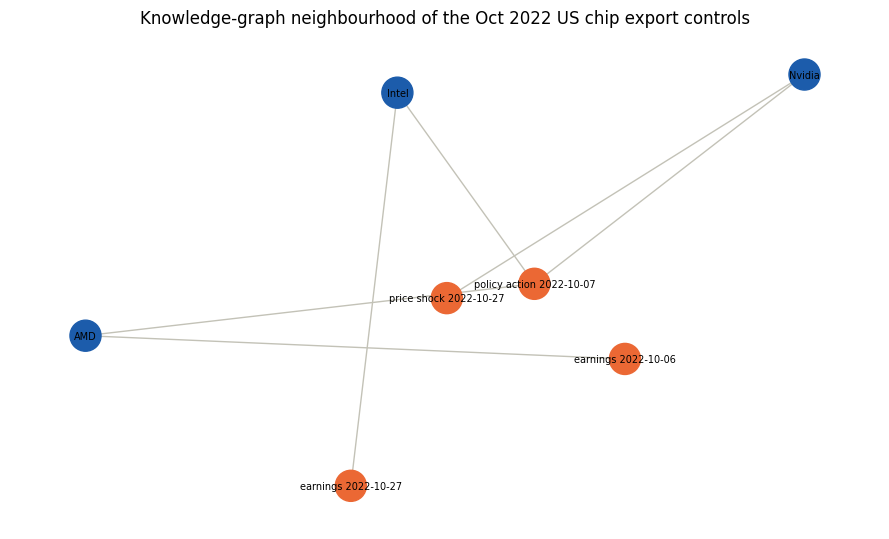

In [13]:
# Figure: the October 2022 export-control action and its neighbourhood
try:
    hub = "event:pol_03"
    sub_nodes = {hub} | set(G.successors(hub)) | set(G.predecessors(hub))
    for c in [n for n in G.successors(hub) if n.startswith("company:")]:
        sd = [u for u, v, a in G.in_edges(c, data=True) if a.get("rel") == "AFFECTS" and u.startswith("event:")
              and "2022-10-0" <= G.nodes[u].get("date", "") <= "2022-10-31" and u != hub][:2]
        sub_nodes |= set(sd)
    H = G.subgraph(sub_nodes).copy()
    pos = nx.spring_layout(H, seed=3, k=1.2)
    col = {"Company": "#1c5cab", "Event": "#eb6834", "Entity": "#86b6ef", "Document": "#c3c2b7", "Month": "#e1e0d9"}
    fig, ax = plt.subplots(figsize=(9, 5.5))
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#c3c2b7", arrows=False)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_color=[col.get(H.nodes[n].get("type"), "#999") for n in H], node_size=500)
    lab = {n: (H.nodes[n].get("name") or (H.nodes[n].get("kind", "") + " " + H.nodes[n].get("date", ""))).strip()[:28] for n in H}
    nx.draw_networkx_labels(H, pos, lab, font_size=7, ax=ax)
    ax.set_title("Knowledge-graph neighbourhood of the Oct 2022 US chip export controls"); ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT / "figures" / "graph_export_controls.png", dpi=160); plt.show()
except Exception:
    traceback.print_exc()

## Step 9 — New analyses: social media vs prices and news, and events by driver

* **Tweets vs abnormal returns.** Tweets have exact timestamps, so every tweet in S_t was posted before day t's close. Lags k ≥ 1 are therefore a clean test of whether social mood **predicts** returns.
* **Social vs news.** Does Twitter mood lead news tone, or follow it?
* **Event study by driver**, using the LLM's categories.

In [14]:
try:
    ar_long = prices[prices.ticker != "QQQ"][["date", "ticker", "ar"]].copy()
    ar_long["date"] = pd.to_datetime(ar_long.date).astype("datetime64[ns]")
    def daily(src):
        d = chunks_v2[chunks_v2.source == src].groupby(["ticker", "day0"]).score.mean().rename(f"s_{src}").reset_index()
        d = d.rename(columns={"day0": "date"}); d["date"] = pd.to_datetime(d.date).astype("datetime64[ns]")
        return d
    S = ar_long.merge(daily("social"), on=["date", "ticker"], how="left").merge(daily("news"), on=["date", "ticker"], how="left")
    rows = []
    for k in range(-3, 4):
        xs, ys, xs2, ys2 = [], [], [], []
        for t, g in S.sort_values("date").groupby("ticker"):
            ark = g.ar.shift(-k); newsk = g.s_news.shift(-k)
            ok = g.s_social.notna() & ark.notna()
            if ok.sum() >= 30:
                xs.append(g.s_social[ok] - g.s_social[ok].mean()); ys.append(ark[ok] - ark[ok].mean())
            ok2 = g.s_social.notna() & newsk.notna()
            if ok2.sum() >= 30:
                xs2.append(g.s_social[ok2] - g.s_social[ok2].mean()); ys2.append(newsk[ok2] - newsk[ok2].mean())
        r1 = np.corrcoef(np.concatenate(xs), np.concatenate(ys))[0, 1] if xs else np.nan
        n1 = sum(len(x) for x in xs)
        r2 = np.corrcoef(np.concatenate(xs2), np.concatenate(ys2))[0, 1] if xs2 else np.nan
        n2 = sum(len(x) for x in xs2)
        rows.append({"k": k, "r_social_vs_AR": r1, "n1": n1, "r_social_vs_news": r2, "n2": n2})
    ll = pd.DataFrame(rows); ll["band_95_AR"] = 1.96 / np.sqrt(ll.n1.clip(lower=1))
    ll.to_csv(OUT / "analysis" / "social_lead_lag.csv", index=False)
    print("Correlation of daily tweet sentiment S_t with AR_{t+k} and with news sentiment_{t+k}:\n", ll.round(4).to_string(index=False))
    SUMMARY["social_lead_lag"] = ll.set_index("k")[["r_social_vs_AR", "r_social_vs_news"]].round(4).to_dict("index")
    SUMMARY["social_n_days"] = int(ll.n1.max())
except Exception:
    traceback.print_exc()

try:
    es = events_v2[~events_v2.ticker_scope.isin(["ALL"]) & events_v2.category.notna() & events_v2.car_m1_p3.notna()]
    by_cat = es.groupby("category").agg(n=("car_m1_p3", "size"), mean_abs_CAR=("car_m1_p3", lambda x: x.abs().mean()),
                                        share_negative=("car_m1_p3", lambda x: (x < 0).mean())).sort_values("n", ascending=False).round(4)
    print("\nEvent study by driver category (LLM-assigned):\n", by_cat.to_string())
    by_cat.to_csv(OUT / "analysis" / "event_study_by_category.csv")
    SUMMARY["event_study_by_category"] = by_cat.to_dict("index")
except Exception:
    traceback.print_exc()

Correlation of daily tweet sentiment S_t with AR_{t+k} and with news sentiment_{t+k}:
  k  r_social_vs_AR   n1  r_social_vs_news  n2  band_95_AR
-3          0.0286 2110            0.0018 917      0.0427
-2          0.0048 2110            0.0711 922      0.0427
-1          0.0293 2110            0.1064 927      0.0427
 0          0.1139 2110            0.1630 931      0.0427
 1          0.0060 2110            0.0102 930      0.0427
 2         -0.0038 2110            0.0059 930      0.0427
 3         -0.0178 2110           -0.0338 935      0.0427

Event study by driver category (LLM-assigned):
                         n  mean_abs_CAR  share_negative
category                                               
earnings              127        0.0744          0.4331
unclear                88        0.0425          0.4432
macro/market-wide      61        0.0473          0.5574
executive/leadership   55        0.0368          0.5455
product/technology     39        0.0507          0.3590
guidance

In [15]:
# ---------------- SAVE + SUMMARY ----------------
chunks_v2.drop(columns=["month"]).to_parquet(OUT / "chunks_v2.parquet", index=False)
np.save(OUT / "embeddings_v2.npy", E2)
events_v2.to_parquet(OUT / "events_v2.parquet", index=False)
if len(releases): releases.drop(columns=["text"]).to_parquet(OUT / "releases.parquet", index=False)
if len(xbrl): xbrl.to_parquet(OUT / "xbrl_quarterly.parquet", index=False)
if len(release_facts): release_facts.to_parquet(OUT / "release_facts.parquet", index=False)
shutil.copy(find_input("prices.parquet"), OUT / "prices.parquet")
shutil.copy(find_input("trading_days.parquet"), OUT / "trading_days.parquet")
manifest = {"created": pd.Timestamp.now(tz="Asia/Kolkata").isoformat(), "embedder": EMBED_MODEL, "query_prefix": QUERY_PREFIX,
            "llm_event_model": LLM_MODEL, "tickers": TICKERS, "policy_events": POLICY_EVENTS,
            "fomc_dates": [str(d.date()) for d in FOMC_DATES], "min_month_docs": MIN_MONTH_DOCS}
(OUT / "manifest_v2.json").write_text(json.dumps(manifest, indent=2, default=str))
for f in sorted(OUT.rglob("*")):
    if f.is_file(): print(f"{str(f.relative_to(OUT)):40s} {f.stat().st_size/1e6:8.2f} MB")
SUMMARY["total_minutes"] = round((time.time() - T0) / 60, 1)
print("\n" + "=" * 30 + " SUMMARY (send this back) " + "=" * 30)
print(json.dumps(SUMMARY, indent=1, default=str))

analysis/event_study_by_category.csv         0.00 MB
analysis/social_lead_lag.csv                 0.00 MB
chunks_v2.parquet                           49.46 MB
coverage_v2.csv                              0.00 MB
embeddings_v2.npy                          165.97 MB
events_v2.parquet                            0.07 MB
figures/graph_export_controls.png            0.07 MB
graph/edges.parquet                          0.07 MB
graph/graph.pkl                              0.55 MB
graph/nodes.parquet                          0.08 MB
manifest_v2.json                             0.00 MB
prices.parquet                               0.83 MB
release_facts.parquet                        0.01 MB
releases.parquet                             0.01 MB
sentiment_monthly_v2.parquet                 0.01 MB
trading_days.parquet                         0.01 MB
xbrl_quarterly.parquet                       0.01 MB

============================== SUMMARY (send this back) ==============================
{
 "tweets"